In [1]:
import cv2
import numpy as np
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path


In [2]:
# class BrailleGenerator:
#     def __init__(self, img_size=(1448, 1024), scale=10):
#         self.img_size = img_size
#         self.scale = scale
        
#         # Standard Marburg Medium dimensions (mm)
#         self.dot_rad = (1.5 / 2) * self.scale
#         self.px_h_dot = 2.5 * self.scale
#         self.px_v_dot = 2.5 * self.scale
#         self.px_cell_w = 6.0 * self.scale
#         self.px_line_h = 10.0 * self.scale

#     def id_to_bits(self, char_id):
#         """
#         Converts ID (0-62) to 6-bit string, then reverses it for dot mapping.
#         Example: 23 -> '010111' -> reversed -> '111010'
#         """
#         char_id = char_id - 1
#         binary = format(char_id, '06b')
#         return binary[::-1]  # Reverse the string

#     def create_soft_bump(self, radius):
#         size = int(radius * 4) 
#         if size % 2 == 0: size += 1
#         kernel = np.zeros((size, size), dtype=np.float32)
#         center = size // 2
#         for i in range(size):
#             for j in range(size):
#                 d = np.sqrt((i - center)**2 + (j - center)**2)
#                 if d < radius:
#                     kernel[i,j] = np.cos(min(1, d/radius) * (np.pi/2))**1.2
#         return kernel

#     def generate_page(self, allowed_chars=None, margin_mm=20, space_prob=0.2):
#         """
#         Args:
#             allowed_chars: List of ints (0-62). If None, uses all.
#             space_prob: Probability (0-1) of a cell being a blank space.
#         """
#         if allowed_chars is None:
#             allowed_chars = list(range(63))

#         recto_h = np.zeros(self.img_size, dtype=np.float32)
#         verso_h = np.zeros(self.img_size, dtype=np.float32)
        
#         bump = self.create_soft_bump(self.dot_rad)
#         bh, bw = bump.shape
#         offset = bh // 2

#         margin = int(margin_mm * self.scale)
#         cols = int((self.img_size[1] - (2 * margin)) // self.px_cell_w)
#         rows = int((self.img_size[0] - (2 * margin)) // self.px_line_h)

#         for r in range(rows):
#             for c in range(cols):
#                 px = margin + (c * self.px_cell_w)
#                 py = margin + (r * self.px_line_h)
                
#                 # --- Recto (Front) ---
#                 # Randomly decide if this cell is a space
#                 if random.random() > space_prob:
#                     char_id = random.choice(allowed_chars)
#                     bit_str = self.id_to_bits(char_id)
                    
#                     for i, bit in enumerate(bit_str):
#                         if bit == '1':
#                             dx = (i // 3) * self.px_h_dot
#                             dy = (i % 3) * self.px_v_dot
#                             y, x = int(py + dy), int(px + dx)
                            
#                             # Place bump
#                             y1, y2, x1, x2 = y-offset, y+offset+1, x-offset, x+offset+1
#                             if 0 <= y1 and y2 < self.img_size[0] and 0 <= x1 and x2 < self.img_size[1]:
#                                 recto_h[y1:y2, x1:x2] = np.maximum(recto_h[y1:y2, x1:x2], bump)

#                 # --- Verso (Back - Interpoint) ---
#                 # Offset verso by half the cell/line spacing
#                 if random.random() > space_prob:
#                     v_char_id = random.choice(allowed_chars)
#                     v_bit_str = self.id_to_bits(v_char_id)
#                     vx_base = px + (self.px_cell_w / 2)
#                     vy_base = py + (self.px_line_h / 2)

#                     for i, bit in enumerate(v_bit_str):
#                         if bit == '1':
#                             dx = (i // 3) * self.px_h_dot
#                             dy = (i % 3) * self.px_v_dot
#                             y, x = int(vy_base + dy), int(vx_base + dx)
                            
#                             y1, y2, x1, x2 = y-offset, y+offset+1, x-offset, x+offset+1
#                             if 0 <= y1 and y2 < self.img_size[0] and 0 <= x1 and x2 < self.img_size[1]:
#                                 verso_h[y1:y2, x1:x2] = np.maximum(verso_h[y1:y2, x1:x2], bump)

#         # Rendering
#         total_h = (recto_h * 1.0) - (verso_h * 0.45) # Slight depth for verso
#         total_h = cv2.GaussianBlur(total_h, (3, 3), 0)

#         dzdx = cv2.Sobel(total_h, cv2.CV_32F, 1, 0, ksize=3)
#         dzdy = cv2.Sobel(total_h, cv2.CV_32F, 0, 1, ksize=3)
        
#         L = np.array([-0.6, -0.6, 0.8], dtype=np.float32)
#         L /= np.linalg.norm(L)
#         mag = np.sqrt(dzdx**2 + dzdy**2 + 1)
#         nx, ny, nz = -dzdx/mag, -dzdy/mag, 1/mag
        
#         diffuse = (nx * L[0] + ny * L[1] + nz * L[2])
#         final = 0.88 + (diffuse - 1.0) * 0.25
#         final += np.random.normal(0, 0.01, self.img_size)
        
#         return (np.clip(final, 0, 1) * 255).astype(np.uint8)

In [ ]:
class BrailleGenerator:
    def __init__(self, img_size=(1448, 1024), scale=5, bbox_pad_mm=0.25):
        self.img_size = img_size
        self.scale = scale
        self.bbox_pad = bbox_pad_mm * self.scale
        
        # Standard Marburg Medium dimensions (mm)
        self.dot_rad = (1.5 / 2) * self.scale
        self.px_h_dot = 2.5 * self.scale
        self.px_v_dot = 2.5 * self.scale
        self.px_cell_w = 6.0 * self.scale
        self.px_line_h = 10.0 * self.scale

    def id_to_bits(self, char_id):
        char_id = max(0, min(62, char_id))
        binary = format(char_id + 1, '06b')
        return binary[::-1] 

    def create_soft_bump(self, radius):
        size = int(radius * 4) 
        if size % 2 == 0: size += 1
        kernel = np.zeros((size, size), dtype=np.float32)
        center = size // 2
        for i in range(size):
            for j in range(size):
                d = np.sqrt((i - center)**2 + (j - center)**2)
                if d < radius:
                    kernel[i,j] = np.cos(min(1, d/radius) * (np.pi/2))**1.4 
        return kernel

    def apply_vignette(self, img, strength=0.2):
        rows, cols = img.shape[:2]
        kernel_x = cv2.getGaussianKernel(cols, cols/2)
        kernel_y = cv2.getGaussianKernel(rows, rows/2)
        vignette = kernel_y * kernel_x.T
        vignette = vignette / vignette.max()
        # Expand dims so vignette broadcasts correctly over 3 channels if passed a color image, 
        # but here we pass the 2D heightmap so it works out of the box.
        return img * ((1 - strength) + strength * vignette)

    def generate_paper_texture(self):
        texture = np.full(self.img_size, 0.99, dtype=np.float32)
        grain = np.random.normal(0, 0.035, self.img_size)
        small_noise = np.random.normal(0, 0.08, (self.img_size[0]//20, self.img_size[1]//20))
        clouds = cv2.resize(small_noise, (self.img_size[1], self.img_size[0]), interpolation=cv2.INTER_CUBIC)
        clouds = cv2.GaussianBlur(clouds, (15, 15), 0)
        return texture + grain + (clouds * 0.001)

    def apply_color_tint(self, img):
        """
        Applies a random color tint from Cool (-1.0) to Warm (1.0).
        img must be a 3-channel Float32 BGR image.
        """
        temp = random.uniform(-1.0, 1.0)
        brightness = random.uniform(0.85, 1.0) 
        
        if temp > 0:
            # Warm: Pull down Blue and Green slightly, keep Red high
            b_mult = 1.0 - (temp * 0.25)
            g_mult = 1.0 - (temp * 0.10)
            r_mult = 1.0
        else:
            # Cool: Pull down Red and Green slightly, keep Blue high
            b_mult = 1.0
            g_mult = 1.0 - (abs(temp) * 0.05)
            r_mult = 1.0 - (abs(temp) * 0.20)
            
        # Apply tint and global darkening (assuming BGR channel order for OpenCV)
        img[:, :, 0] *= (b_mult * brightness)
        img[:, :, 1] *= (g_mult * brightness)
        img[:, :, 2] *= (r_mult * brightness)
        
        return img

    def apply_perspective_skew(self, img, max_skew_px=180, max_rot_deg=2.5):
        """
        Applies realistic 3D camera perspectives and 2D rotations.
        max_skew_px: Controls the maximum pixel distortion for pitch/yaw.
        max_rot_deg: Controls the maximum degree of page rotation.
        """
        h, w = img.shape[:2]
        skew_factor = max_skew_px * (self.scale / 10) 
        
        src_pts = np.float32([[0, 0], [w-1, 0], [0, h-1], [w-1, h-1]])
        dst_pts = np.float32([[0, 0], [w-1, 0], [0, h-1], [w-1, h-1]])
        
        transform_style = random.choice(['3d_pitch', '3d_yaw', '3d_combined', '2d_rotate'])
        
        if transform_style == '3d_pitch':
            # Trapezoid: Camera tilted up or down
            # Widened range: 0.2 (mild) to 2.5 (extreme)
            tilt = random.uniform(skew_factor * 0.2, skew_factor * 2.5)
            if random.choice([True, False]): # Top edge further away
                dst_pts[0][0] += tilt; dst_pts[1][0] -= tilt  
                dst_pts[0][1] += tilt; dst_pts[1][1] += tilt  
            else: # Bottom edge further away
                dst_pts[2][0] += tilt; dst_pts[3][0] -= tilt  
                dst_pts[2][1] -= tilt; dst_pts[3][1] -= tilt  
                
        elif transform_style == '3d_yaw':
            # Trapezoid: Camera panned left or right
            tilt = random.uniform(skew_factor * 0.2, skew_factor * 2.5)
            if random.choice([True, False]): # Left edge further away
                dst_pts[0][1] += tilt; dst_pts[2][1] -= tilt  
                dst_pts[0][0] += tilt; dst_pts[2][0] += tilt  
            else: # Right edge further away
                dst_pts[1][1] += tilt; dst_pts[3][1] -= tilt  
                dst_pts[1][0] -= tilt; dst_pts[3][0] -= tilt  

        elif transform_style == '3d_combined':
            # Diagonal Perspective: Looking from a specific corner
            px = random.uniform(skew_factor * 0.5, skew_factor * 2.0)
            py = random.uniform(skew_factor * 0.5, skew_factor * 2.0)
            corner = random.choice([0, 1, 2, 3])
            
            # Pushing adjacent corners slightly more to maintain realistic perspective flow
            if corner == 0: # Top-Left furthest away
                dst_pts[0][0] += px; dst_pts[0][1] += py
                dst_pts[1][1] += py * 0.6; dst_pts[2][0] += px * 0.6
            elif corner == 1: # Top-Right furthest away
                dst_pts[1][0] -= px; dst_pts[1][1] += py
                dst_pts[0][1] += py * 0.6; dst_pts[3][0] -= px * 0.6
            elif corner == 2: # Bottom-Left furthest away
                dst_pts[2][0] += px; dst_pts[2][1] -= py
                dst_pts[0][0] += px * 0.6; dst_pts[3][1] -= py * 0.6
            else: # Bottom-Right furthest away
                dst_pts[3][0] -= px; dst_pts[3][1] -= py
                dst_pts[1][0] -= px * 0.6; dst_pts[2][1] -= py * 0.6
                
        elif transform_style == '2d_rotate':
            # True Rigid Rotation (Wider angle range)
            angle_deg = random.uniform(-max_rot_deg, max_rot_deg) 
            angle_rad = np.radians(angle_deg)
            cx, cy = w / 2, h / 2
            
            for i in range(4):
                x, y = src_pts[i]
                rx = cx + (x - cx) * np.cos(angle_rad) - (y - cy) * np.sin(angle_rad)
                ry = cy + (x - cx) * np.sin(angle_rad) + (y - cy) * np.cos(angle_rad)
                dst_pts[i] = [rx, ry]

        M = cv2.getPerspectiveTransform(src_pts, dst_pts)
        warped = cv2.warpPerspective(img, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
        return warped, M

    def calculate_lighting(self, total_h, azimuth_deg=225, elevation_deg=45, intensity=0.3):
        dzdx = cv2.Sobel(total_h, cv2.CV_32F, 1, 0, ksize=3)
        dzdy = cv2.Sobel(total_h, cv2.CV_32F, 0, 1, ksize=3)
        
        az = np.radians(azimuth_deg)
        el = np.radians(elevation_deg)
        L = np.array([np.cos(el)*np.cos(az), np.cos(el)*np.sin(az), np.sin(el)], dtype=np.float32)
        
        mag = np.sqrt(dzdx**2 + dzdy**2 + 1)
        nx, ny, nz = -dzdx/mag, -dzdy/mag, 1/mag
        
        diffuse = (nx * L[0] + ny * L[1] + nz * L[2])
        return (diffuse - 1.0) * intensity

    def generate_page(self, allowed_chars=None, margin_mm=20, space_prob=0.35, apply_skew=True):
        if allowed_chars is None: allowed_chars = list(range(63))

        recto_h = np.zeros(self.img_size, dtype=np.float32)
        verso_h = np.zeros(self.img_size, dtype=np.float32)
        bump = self.create_soft_bump(self.dot_rad)
        bh, bw = bump.shape
        offset = bh // 2

        margin = int(margin_mm * self.scale)
        cols = int((self.img_size[1] - (2 * margin)) // self.px_cell_w)
        rows = int((self.img_size[0] - (2 * margin)) // self.px_line_h)

        raw_bboxes = [] 

        for r in range(rows):
            for c in range(cols):
                px = margin + (c * self.px_cell_w)
                py = margin + (r * self.px_line_h)
                
                # --- Recto (Front) ---
                if random.random() > space_prob:
                    char_id = int(np.random.choice(allowed_chars))
                    bit_str = self.id_to_bits(char_id)
                    
                    x1 = px - self.dot_rad - self.bbox_pad
                    y1 = py - self.dot_rad - self.bbox_pad
                    x2 = px + self.px_h_dot + self.dot_rad + self.bbox_pad
                    y2 = py + (2 * self.px_v_dot) + self.dot_rad + self.bbox_pad
                    raw_bboxes.append([char_id, x1, y1, x2, y2])
                    
                    for i, bit in enumerate(bit_str):
                        if bit == '1':
                            jitter_x = random.uniform(-0.05, 0.05) * self.scale
                            jitter_y = random.uniform(-0.05, 0.05) * self.scale
                            dx = (i // 3) * self.px_h_dot + jitter_x
                            dy = (i % 3) * self.px_v_dot + jitter_y
                            y, x = int(py + dy), int(px + dx)
                            
                            y1_b, y2_b, x1_b, x2_b = y-offset, y+offset+1, x-offset, x+offset+1
                            if 0 <= y1_b and y2_b < self.img_size[0] and 0 <= x1_b and x2_b < self.img_size[1]:
                                recto_h[y1_b:y2_b, x1_b:x2_b] = np.maximum(recto_h[y1_b:y2_b, x1_b:x2_b], bump)

                # --- Verso (Back - Interpoint) ---
                if random.random() > space_prob:
                    v_char_id = int(np.random.choice(allowed_chars))
                    v_bit_str = self.id_to_bits(v_char_id)
                    vx_base = px + (self.px_cell_w / 2)
                    vy_base = py + (self.px_line_h / 2)

                    for i, bit in enumerate(v_bit_str):
                        if bit == '1':
                            dx = (i // 3) * self.px_h_dot
                            dy = (i % 3) * self.px_v_dot
                            y, x = int(vy_base + dy), int(vx_base + dx)
                            
                            y1_b, y2_b, x1_b, x2_b = y-offset, y+offset+1, x-offset, x+offset+1
                            if 0 <= y1_b and y2_b < self.img_size[0] and 0 <= x1_b and x2_b < self.img_size[1]:
                                verso_h[y1_b:y2_b, x1_b:x2_b] = np.maximum(verso_h[y1_b:y2_b, x1_b:x2_b], bump)

        # ==========================================
        # 2D Rendering & Shading
        # ==========================================
        total_h = (recto_h * 1.0) - (verso_h * 0.40) 
        total_h = cv2.GaussianBlur(total_h, (5, 5), 0) 
        
        # --- Randomize Lighting ---
        # Azimuth: 225 (Top-Left) to 315 (Top-Right)
        light_azimuth = random.uniform(200, 340)
        # Elevation: 35 to 55 degrees (adds slight variation to shadow length/specular hit)
        light_elevation = random.uniform(15, 55)
        # Intensity: Dimmer (0.15) to Brighter (0.45)
        light_intensity = random.uniform(0.15, 0.5)
        
        # Calculate base diffuse lighting
        shading = self.calculate_lighting(
            total_h, 
            azimuth_deg=light_azimuth, 
            elevation_deg=light_elevation, 
            intensity=light_intensity
        )
        
        # --- RECTO TRAILING SHADOW ---
        # Calculate shift distance based on scale
        shadow_dist = 1.2 * self.scale 
        az_rad = np.radians(light_azimuth)
        
        # Shift shadow in the exact opposite direction of the light source
        dx = -np.cos(az_rad) * shadow_dist
        dy = -np.sin(az_rad) * shadow_dist
        
        # Create translation matrix and apply to recto heightmap
        M_shadow = np.float32([[1, 0, dx], [0, 1, dy]])
        recto_shadow = cv2.warpAffine(recto_h, M_shadow, (self.img_size[1], self.img_size[0]))
        
        # Soften the shadow (dynamically size kernel based on scale)
        blur_size = int(self.scale * 2.5)
        if blur_size % 2 == 0: blur_size += 1
        recto_shadow = cv2.GaussianBlur(recto_shadow, (blur_size, blur_size), 0)
        
        # Mask out the bump itself so the shadow only falls on the background paper
        recto_shadow = np.clip(recto_shadow - recto_h, 0, 1)
        
        # Subtract the shadow from the shading layer 
        # (Proportionally scale shadow darkness to the randomized light intensity)
        shadow_intensity = min(light_intensity * random.uniform(0.3, 0.6), 0.15)
        shading -= (recto_shadow * shadow_intensity)
        # -----------------------------
        
        final = self.generate_paper_texture() + shading
        final = self.apply_vignette(final, strength=0.25)
        
        # Expand 2D grayscale to 3-Channel BGR
        final_bgr = np.stack([final, final, final], axis=-1)

        final_bgr = self.apply_color_tint(final_bgr)
        
        M = None
        if apply_skew:
            final_bgr, M = self.apply_perspective_skew(final_bgr, max_skew_px=80,max_rot_deg=2.5)

        # Format Annotations to YOLO
        yolo_annotations = []
        img_h, img_w = final_bgr.shape[:2]

        for box in raw_bboxes:
            char_id, x1, y1, x2, y2 = box
            
            if M is not None:
                pts = np.float32([[x1, y1], [x2, y1], [x2, y2], [x1, y2]]).reshape(-1, 1, 2)
                warped_pts = cv2.perspectiveTransform(pts, M)
                x1 = warped_pts[:, 0, 0].min()
                y1 = warped_pts[:, 0, 1].min()
                x2 = warped_pts[:, 0, 0].max()
                y2 = warped_pts[:, 0, 1].max()

            x1, x2 = max(0, x1), min(img_w, x2)
            y1, y2 = max(0, y1), min(img_h, y2)
            
            w = x2 - x1
            h = y2 - y1
            
            if w <= 0 or h <= 0: continue
            
            xc = x1 + w / 2
            yc = y1 + h / 2
            
            yolo_annotations.append(f"{char_id} {xc/img_w} {yc/img_h} {w/img_w} {h/img_h}")

        final_img_uint8 = (np.clip(final_bgr, 0, 1) * 255).astype(np.uint8)
        return final_img_uint8, yolo_annotations

In [4]:
def visualize_braille_annotations(image, yolo_annotations):
    """
    Plots the image and overlays the YOLO-format bounding boxes.
    """
    fig, ax = plt.subplots(1, figsize=(20, 40))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    # Safely handle both RGB (3 channels) and Grayscale (2 channels)
    if len(image.shape) == 3:
        ax.imshow(image)
        img_h, img_w, _ = image.shape # Unpack 3 values
    else:
        ax.imshow(image, cmap='gray')
        img_h, img_w = image.shape    # Unpack 2 values
    
    for ann in yolo_annotations:
        parts = ann.split()
        char_id = parts[0]
        xc = float(parts[1]) * img_w
        yc = float(parts[2]) * img_h
        w = float(parts[3]) * img_w
        h = float(parts[4]) * img_h
        
        # Calculate top-left corner for matplotlib Rectangle
        x_min = xc - (w / 2)
        y_min = yc - (h / 2)
        
        # Draw the bounding box
        rect = patches.Rectangle(
            (x_min, y_min), w, h, 
            linewidth=0.8, edgecolor='green', facecolor='none', alpha=0.8
        )
        ax.add_patch(rect)
        
        # Add the label ID text just above the box
        ax.text(x_min, y_min - 2, char_id, color='green', fontsize=8, weight='bold')

    plt.axis('off')
    plt.title("Synthetic Braille with Recto Annotations")
    plt.show()

['21 0.06108645349740982 0.09935091435909271 0.024417012929916382 0.02524442784488201', '38 0.14874102175235748 0.09479860216379166 0.024417012929916382 0.02524443343281746', '35 0.17795921862125397 0.09328117221593857 0.024417012929916382 0.02524443343281746', '19 0.20717740058898926 0.09176373481750488 0.024417012929916382 0.02524442784488201', '13 0.2656137943267822 0.08872886002063751 0.024417012929916382 0.025244422256946564']


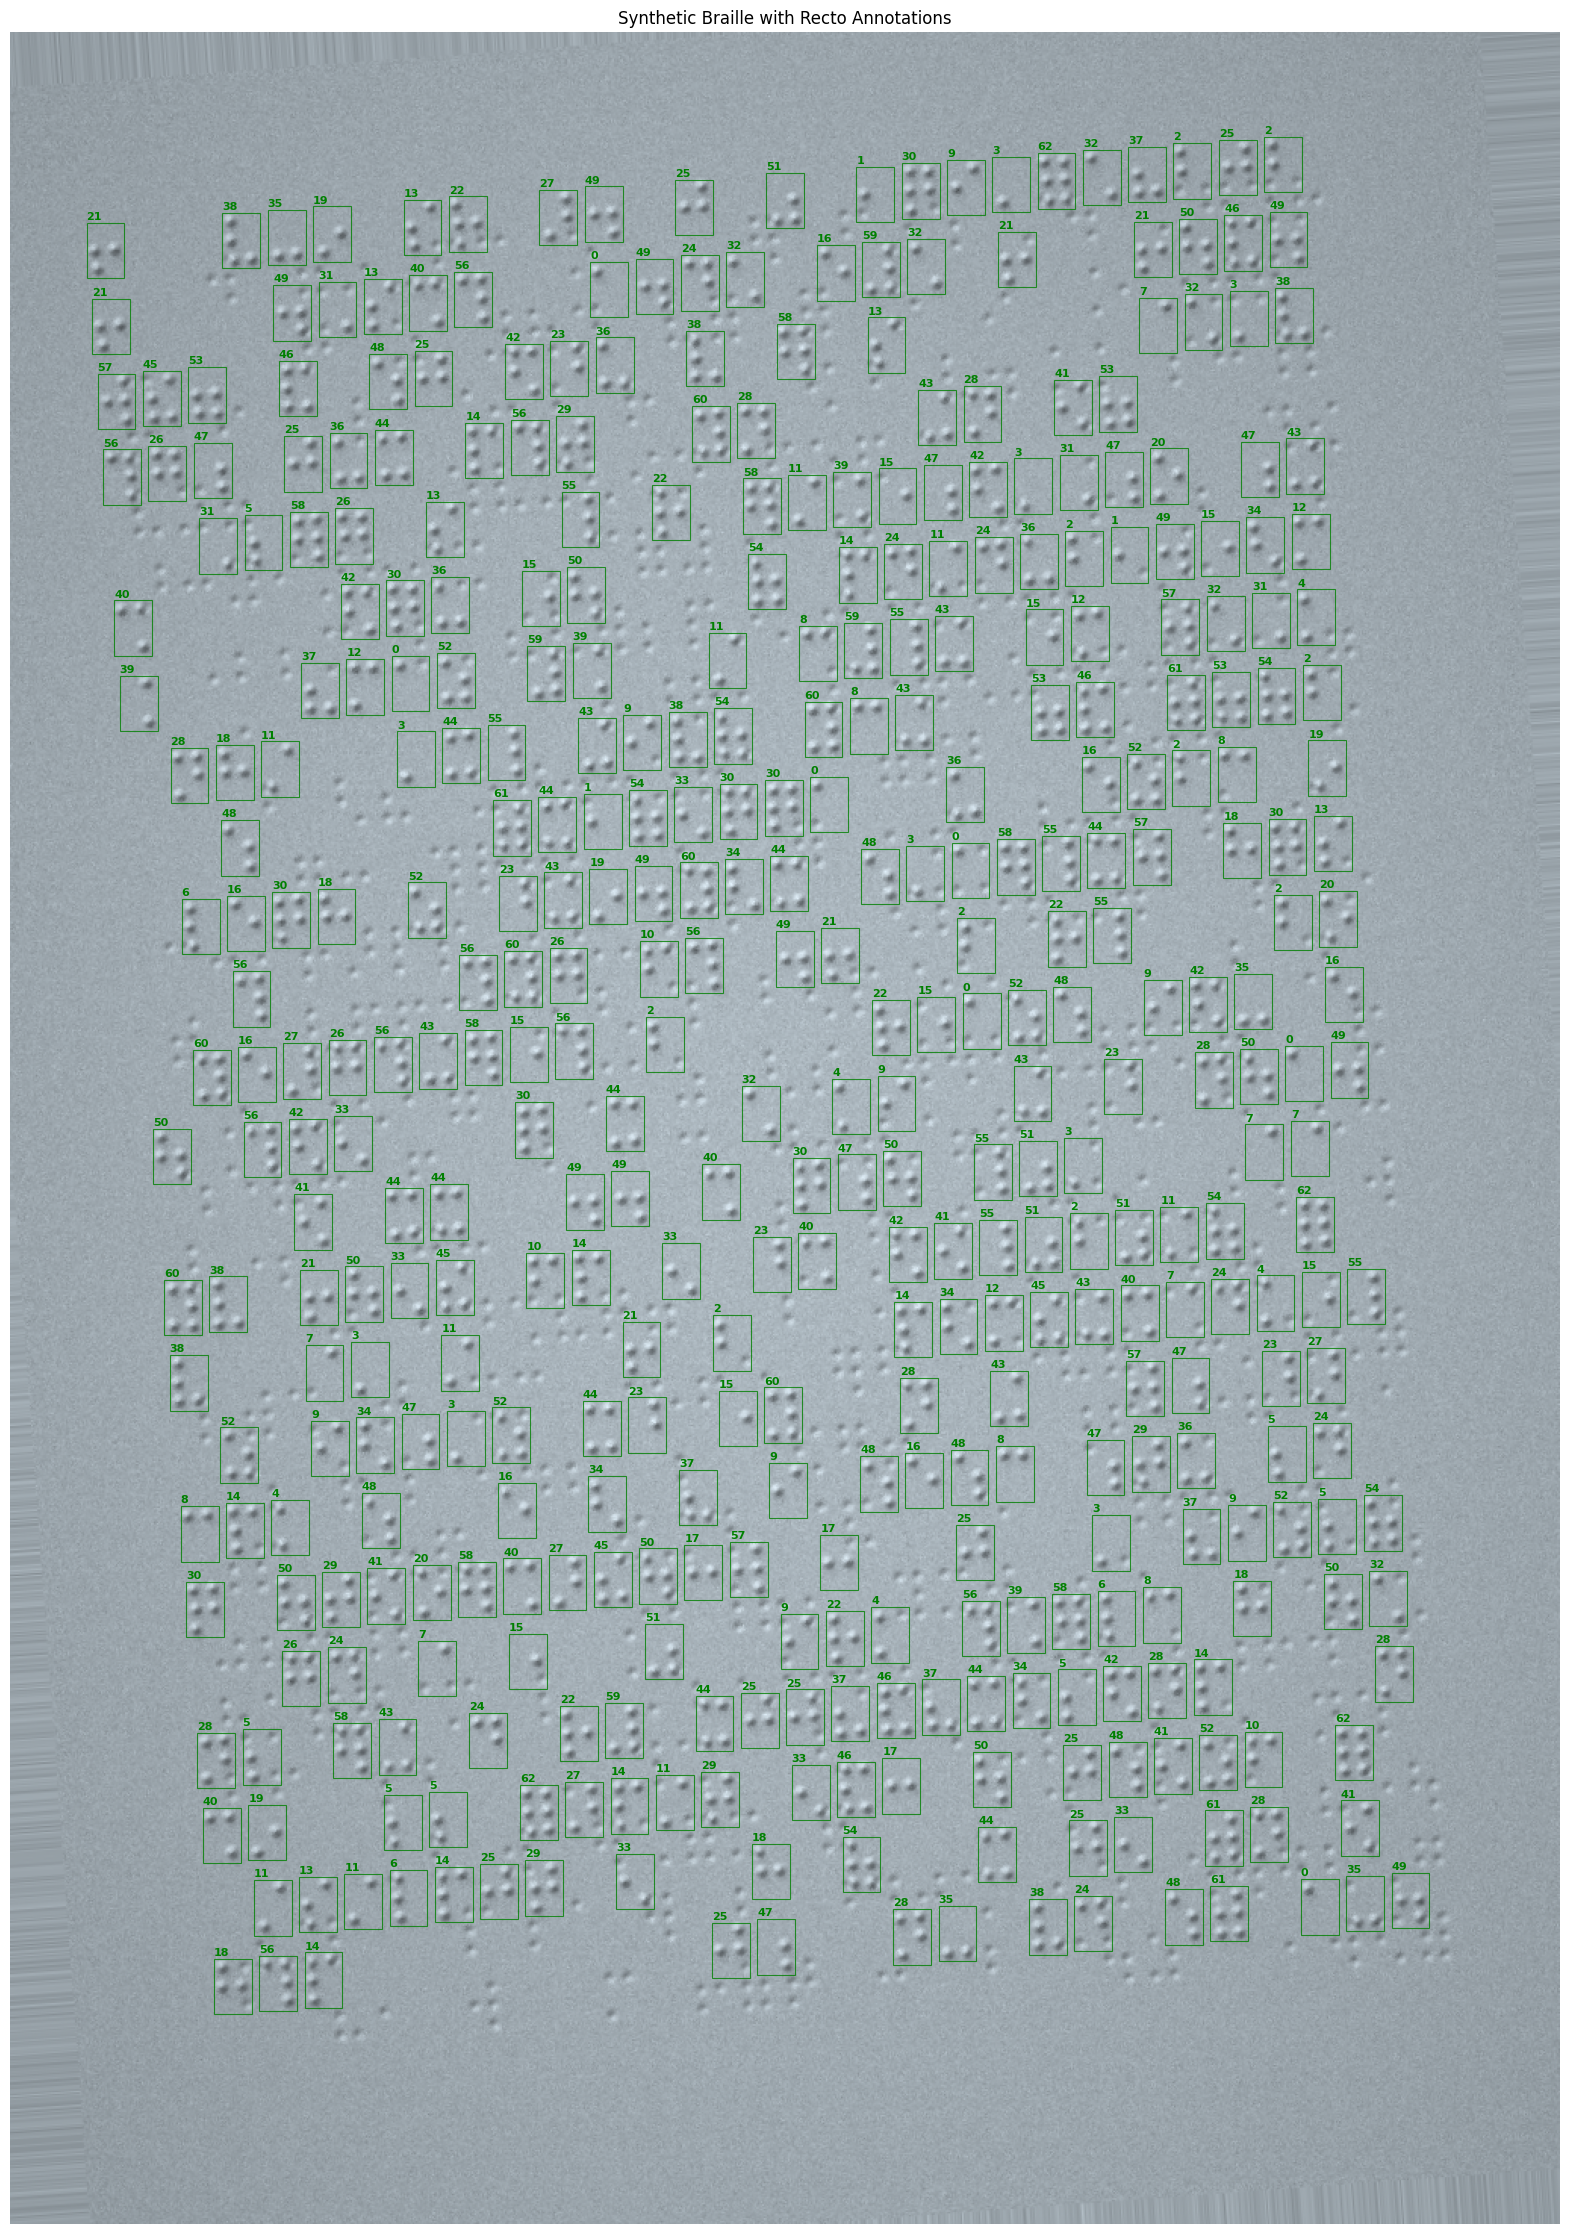

In [5]:
gen = BrailleGenerator(scale=5)
# allowed_chars=[]
img, annotations = gen.generate_page()
print(annotations[:5])
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

cv2.imwrite(img=img, filename="test-synthesized.jpg")
# plt.figure(figsize=(40, 20))
# plt.axis("off")
# plt.imshow(img)
# plt.show()

visualize_braille_annotations(img, annotations)

In [6]:
def build_yolo_dataset(generator, num_samples=100, output_dir="braille_dataset", split_ratios=(0.8, 0.1, 0.1)):
    """
    Generates a dataset and splits it into train/val/test folders.
    split_ratios defines the distribution (Train, Validation, Test).
    """
    # Validate ratios sum to 1.0
    assert abs(sum(split_ratios) - 1.0) < 1e-5, "Split ratios must sum to 1.0"
    
    # Calculate exact counts for each split
    train_count = int(num_samples * split_ratios[0])
    val_count = int(num_samples * split_ratios[1])
    
    # Create a list mapping each sample to a split, then shuffle it
    splits = ['train'] * train_count + ['val'] * val_count
    splits += ['test'] * (num_samples - len(splits)) # Give remainder to test
    random.shuffle(splits)
    
    # Set up directory structure
    base_path = Path(output_dir)
    for folder in ['images', 'labels']:
        for split in ['train', 'val', 'test']:
            (base_path / folder / split).mkdir(parents=True, exist_ok=True)
            
    print(f"Creating {num_samples} samples in '{output_dir}'...")
    
    for i, split in enumerate(splits):
        # Generate the synthetic image and YOLO annotations
        img_bgr, annotations = generator.generate_page()
        
        # Define zero-padded filenames (e.g., sample_00042.jpg)
        base_filename = f"sample_{i:05d}"
        img_path = base_path / 'images' / split / f"{base_filename}.jpg"
        lbl_path = base_path / 'labels' / split / f"{base_filename}.txt"
        
        # Save image using OpenCV
        cv2.imwrite(str(img_path), img_bgr)
        
        # Save annotations as a text file
        with open(lbl_path, 'w') as f:
            # Join list of annotation strings with newlines
            f.write('\n'.join(annotations))
            
        # Optional progress tracking
        if (i + 1) % max(1, (num_samples // 10)) == 0 or (i + 1) == num_samples:
            print(f"Generated {i + 1}/{num_samples}...")

    print("\nDataset Generation Complete!")
    print("-" * 30)
    print(f"Train samples: {splits.count('train')}")
    print(f"Val samples:   {splits.count('val')}")
    print(f"Test samples:  {splits.count('test')}")
    print("-" * 30)

In [7]:
# build_yolo_dataset(
#         generator=gen, 
#         num_samples=500, 
#         output_dir="../data/synthetic", 
#         split_ratios=(0.7, 0.2, 0.1)
#     )